In [1]:
# Run once if a library is missing:
# !pip install rioxarray scikit-image geopandas matplotlib pandas
#%pip install rioxarray
%pip install scikit-image
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rioxarray as rxr
from scipy import ndimage
from skimage.filters import threshold_otsu

# Files exported from GEE (Part A). Keep them next to this notebook.
PRE_FILE  = "srilanka_s1_pre.tif"
POST_FILE = "srilanka_s1_post.tif"
AUX_FILE  = "srilanka_aux.tif"

# Acquisition dates used for the figure titles. EDIT these to match the
# passes you picked in Part A (see the printed pass list in GEE).
PRE_LABEL  = "pre-flood, Nov 2025"
POST_LABEL = "flood, Nov-Dec 2025"
AREA_NAME  = "Central Province, Sri Lanka"

OUT_DIR = "flood_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 110

Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install scikit-image rioxarray geopandas
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rioxarray as rxr
from scipy import ndimage
from skimage.filters import threshold_otsu

# Files exported from GEE (Part A). Keep them next to this notebook.
PRE_FILE  = "srilanka_s1_pre.tif"
POST_FILE = "srilanka_s1_post.tif"
AUX_FILE  = "srilanka_aux.tif"

# EDIT these to the real acquisition dates you used in Part A
PRE_LABEL  = "pre-flood, Nov 2025"
POST_LABEL = "flood, Nov-Dec 2025"
AREA_NAME  = "Central Province, Sri Lanka"

OUT_DIR = "flood_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 110

Note: you may need to restart the kernel to use updated packages.


In [2]:
pre  = rxr.open_rasterio(PRE_FILE,  masked=True)
post = rxr.open_rasterio(POST_FILE, masked=True)
aux  = rxr.open_rasterio(AUX_FILE,  masked=True)

# Make sure every layer sits on exactly the same pixel grid as the pre-flood image
post = post.rio.reproject_match(pre)
aux  = aux.rio.reproject_match(pre)

print("CRS        :", pre.rio.crs)
print("Shape      :", pre.shape, "(bands, rows, cols)")
res = pre.rio.resolution()
PIXEL_AREA = abs(res[0] * res[1])          # m² per pixel
print("Pixel size :", abs(res[0]), "m  ->", PIXEL_AREA, "m² per pixel")

pre_vv,  pre_vh  = pre.sel(band=1).values,  pre.sel(band=2).values
post_vv, post_vh = post.sel(band=1).values, post.sel(band=2).values
jrc   = aux.sel(band=1).values
lc    = aux.sel(band=2).values
slope = aux.sel(band=3).values
elev  = aux.sel(band=4).values
hand  = aux.sel(band=5).values

valid = np.isfinite(pre_vv) & np.isfinite(post_vv)

# Clip to the Central Province boundary (GADM level 1 = provinces).
# This step is optional: if anything is wrong with the shapefile, we print why
# and carry on with the whole exported rectangle.
PROVINCE_FILE  = "gadm41_LKA_1.shp"
PROVINCE_FIELD = "NAME_1"
PROVINCE       = "Central"
try:
    os.environ["SHAPE_RESTORE_SHX"] = "YES"        # rebuild a missing .shx index file
    import geopandas as gpd
    from rasterio import features

    prov = gpd.read_file(PROVINCE_FILE)
    if prov.crs is None:                            # .prj file missing -> GADM is lat/lon
        prov = prov.set_crs("EPSG:4326")
    prov = prov.to_crs(pre.rio.crs)

    if PROVINCE_FIELD not in prov.columns:          # .dbf file missing or different field name
        raise ValueError(f"column '{PROVINCE_FIELD}' not found; columns are {list(prov.columns)}. "
                         "Copy the .dbf file next to the .shp file.")
    prov = prov[prov[PROVINCE_FIELD].astype(str).str.strip().str.lower() == PROVINCE.lower()]
    if len(prov) == 0:
        raise ValueError(f"'{PROVINCE}' not found in column '{PROVINCE_FIELD}'")

    inside = features.rasterize(((g, 1) for g in prov.geometry), out_shape=pre_vv.shape,
                                transform=pre.rio.transform(), fill=0, dtype="uint8").astype(bool)
    valid &= inside
    print(f"Clipped to {PROVINCE} Province boundary")
except Exception as e:
    print("Province clip skipped ->", type(e).__name__, ":", e)
    print("Using the whole exported rectangle instead.")
print(f"Valid pixels: {valid.sum():,} of {valid.size:,}")

# Map extent in km (for axis labels)
xmin, ymin, xmax, ymax = pre.rio.bounds()
EXTENT = [xmin/1000, xmax/1000, ymin/1000, ymax/1000]

CRS        : EPSG:32644
Shape      : (2, 5807, 3869) (bands, rows, cols)
Pixel size : 20.0 m  -> 400.0 m² per pixel
Province clip skipped -> ValueError : column 'NAME_1' not found; columns are ['geometry']. Copy the .dbf file next to the .shp file.
Using the whole exported rectangle instead.
Valid pixels: 22,433,235 of 22,467,283


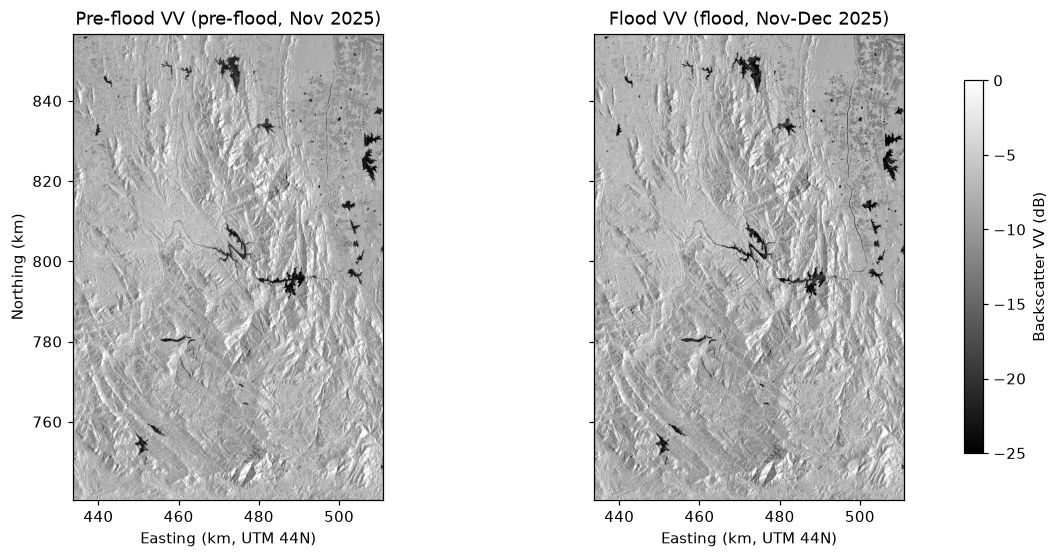

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, img, title in zip(axes, [pre_vv, post_vv],
                          [f"Pre-flood VV ({PRE_LABEL})", f"Flood VV ({POST_LABEL})"]):
    im = ax.imshow(img, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
    ax.set_title(title)
    ax.set_xlabel("Easting (km, UTM 44N)")
axes[0].set_ylabel("Northing (km)")
fig.colorbar(im, ax=axes, shrink=0.8, label="Backscatter VV (dB)")
plt.savefig(f"{OUT_DIR}/01_pre_vs_post.png", dpi=200, bbox_inches="tight")
plt.show()

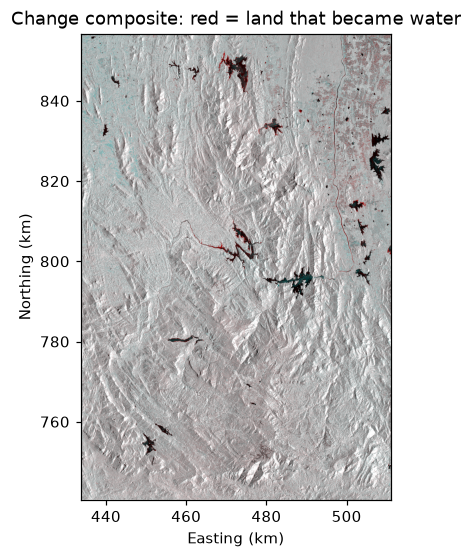

In [4]:
def to01(db, lo=-25, hi=0):
    return np.clip((db - lo) / (hi - lo), 0, 1)

rgb = np.dstack([to01(pre_vv), to01(post_vv), to01(post_vv)])
rgb[~valid] = 1

plt.figure(figsize=(10, 5.5))
plt.imshow(rgb, extent=EXTENT)
plt.title("Change composite: red = land that became water")
plt.xlabel("Easting (km)"); plt.ylabel("Northing (km)")
plt.savefig(f"{OUT_DIR}/02_change_rgb.png", dpi=200, bbox_inches="tight")
plt.show()

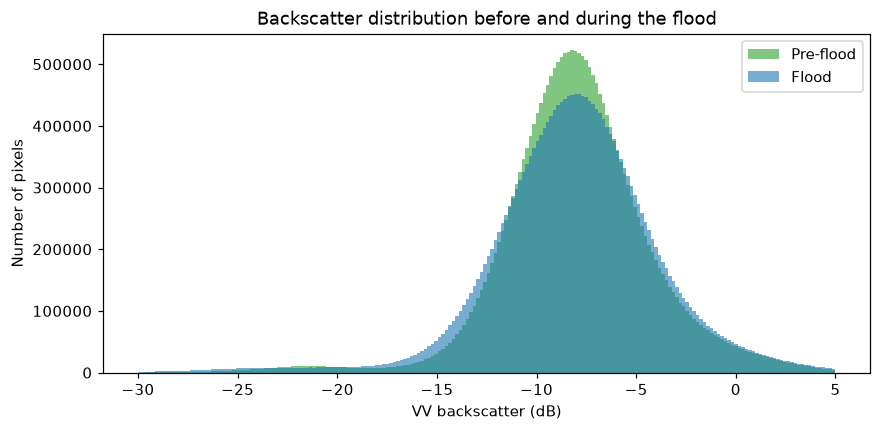

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pre_vv[valid],  bins=200, range=(-30, 5), alpha=0.6, label="Pre-flood",  color="tab:green")
ax.hist(post_vv[valid], bins=200, range=(-30, 5), alpha=0.6, label="Flood",      color="tab:blue")
ax.set_xlabel("VV backscatter (dB)"); ax.set_ylabel("Number of pixels")
ax.set_title("Backscatter distribution before and during the flood")
ax.legend()
plt.show()

In [6]:
def lee_filter(img_db, size=5, enl=4.4):
    """Lee speckle filter.
    img_db : 2-D array in dB (NaN = no data)
    size   : moving window size in pixels
    enl    : equivalent number of looks (~4.4 for Sentinel-1 IW GRD)
    """
    lin = np.power(10.0, img_db / 10.0)          # dB -> linear power
    ok = np.isfinite(lin)
    z = np.where(ok, lin, 0.0)

    with np.errstate(invalid="ignore", divide="ignore"):
        n     = ndimage.uniform_filter(ok.astype(float), size)
        mean  = ndimage.uniform_filter(z, size) / n
        mean2 = ndimage.uniform_filter(z * z, size) / n
        var_z = np.maximum(mean2 - mean**2, 0)

        cu2 = 1.0 / enl                            # speckle variation coefficient²
        var_x = np.maximum((var_z - mean**2 * cu2) / (1 + cu2), 0)
        k = np.where(var_z > 0, var_x / var_z, 0)  # 0 = smooth fully, 1 = keep pixel
        out = mean + k * (z - mean)

    out = np.where(ok & (out > 0), out, np.nan)
    return 10 * np.log10(out)                      # back to dB

pre_vv_f  = lee_filter(pre_vv)
post_vv_f = lee_filter(post_vv)
pre_vh_f  = lee_filter(pre_vh)
post_vh_f = lee_filter(post_vh)
print("Speckle filtering done")

Speckle filtering done


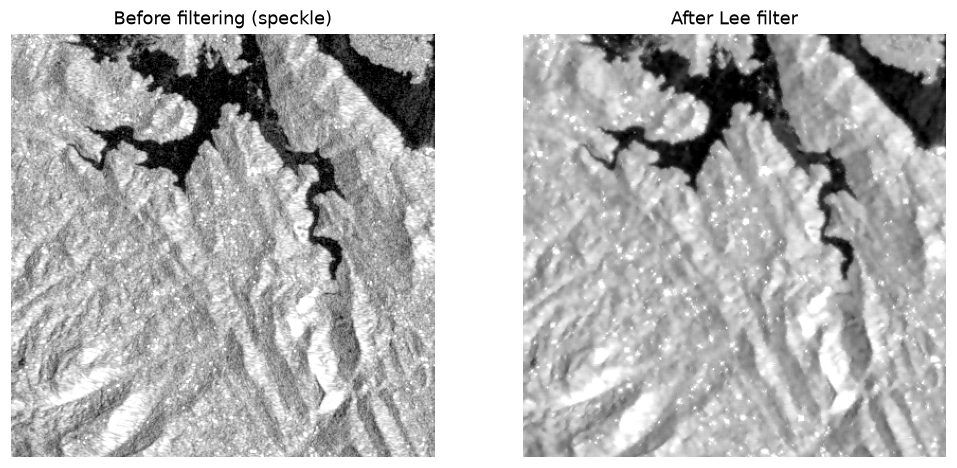

In [7]:
# Zoom into the centre of the image to see the difference
r0, c0 = pre_vv.shape[0] // 2, pre_vv.shape[1] // 2
win = np.s_[max(r0-200, 0):r0+200, max(c0-200, 0):c0+200]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(post_vv[win],   cmap="gray", vmin=-25, vmax=0); axes[0].set_title("Before filtering (speckle)")
axes[1].imshow(post_vv_f[win], cmap="gray", vmin=-25, vmax=0); axes[1].set_title("After Lee filter")
for ax in axes: ax.axis("off")
plt.savefig(f"{OUT_DIR}/03_speckle_filter.png", dpi=200, bbox_inches="tight")
plt.show()

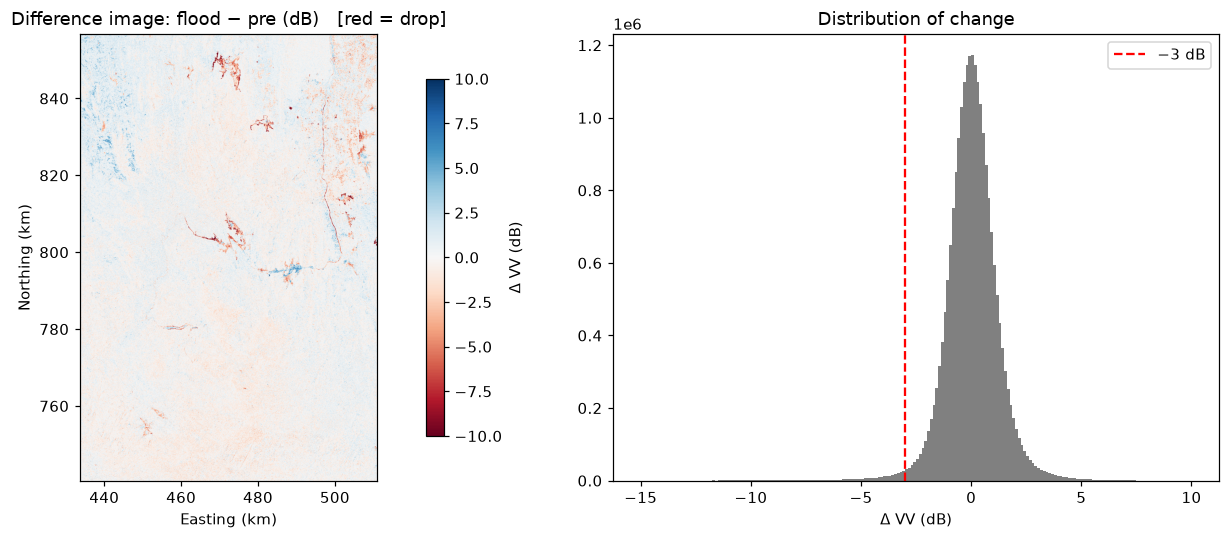

In [8]:
diff = post_vv_f - pre_vv_f

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
im = axes[0].imshow(diff, cmap="RdBu", vmin=-10, vmax=10, extent=EXTENT)
axes[0].set_title("Difference image: flood − pre (dB)   [red = drop]")
axes[0].set_xlabel("Easting (km)"); axes[0].set_ylabel("Northing (km)")
fig.colorbar(im, ax=axes[0], shrink=0.8, label="Δ VV (dB)")

axes[1].hist(diff[np.isfinite(diff)], bins=200, range=(-15, 10), color="grey")
axes[1].axvline(-3, color="red", ls="--", label="−3 dB")
axes[1].set_xlabel("Δ VV (dB)"); axes[1].set_title("Distribution of change")
axes[1].legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_difference.png", dpi=200, bbox_inches="tight")
plt.show()

Otsu water threshold: -7.84 dB
Otsu value outside the expected range -> using -18 dB instead
Using: water if VV < -18.00 dB  AND  change < -3.0 dB


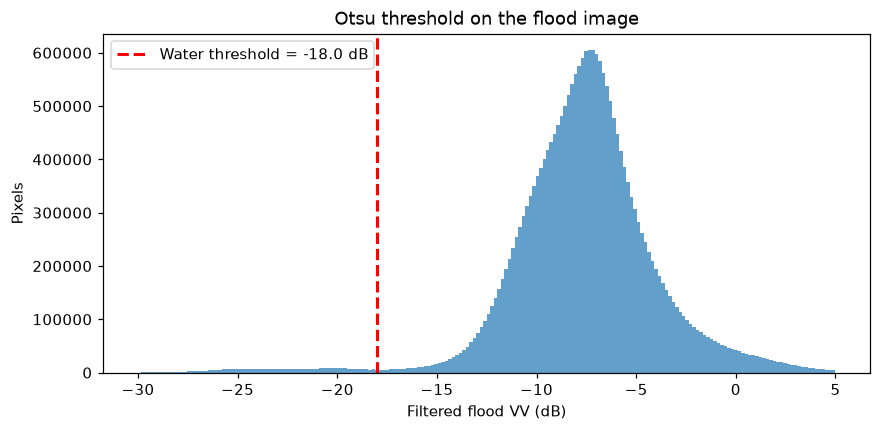

In [9]:
# --- Threshold 1: water threshold from Otsu on the filtered flood image ---
vals = post_vv_f[np.isfinite(post_vv_f)]
rng = np.random.default_rng(42)
sample = rng.choice(vals, size=min(2_000_000, vals.size), replace=False)
t_otsu = threshold_otsu(sample)
print(f"Otsu water threshold: {t_otsu:.2f} dB")

# Sanity check: open water in VV is normally between about -24 and -15 dB.
# If Otsu falls outside this range, the histogram is not clearly bimodal.
if -24 <= t_otsu <= -14:
    T_WATER = t_otsu
else:
    T_WATER = -18.0
    print("Otsu value outside the expected range -> using -18 dB instead")

# --- Threshold 2: minimum backscatter drop ---
T_DIFF = -3.0

print(f"Using: water if VV < {T_WATER:.2f} dB  AND  change < {T_DIFF} dB")

plt.figure(figsize=(9, 4))
plt.hist(vals, bins=200, range=(-30, 5), color="tab:blue", alpha=0.7)
plt.axvline(T_WATER, color="red", ls="--", lw=2, label=f"Water threshold = {T_WATER:.1f} dB")
plt.xlabel("Filtered flood VV (dB)"); plt.ylabel("Pixels")
plt.title("Otsu threshold on the flood image"); plt.legend()
plt.savefig(f"{OUT_DIR}/05_otsu.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
water_now  = post_vv_f < T_WATER
became_dark = diff < T_DIFF
flood_raw = water_now & became_dark & valid

print(f"Raw flood pixels: {flood_raw.sum():,}  ->  {flood_raw.sum()*PIXEL_AREA/1e4:,.0f} ha")

Raw flood pixels: 129,309  ->  5,172 ha


In [11]:
PERM_WATER_PCT = 50     # JRC occurrence %
MAX_SLOPE      = 5      # degrees
MAX_HAND       = 15     # metres above nearest drainage
MIN_PIXELS     = 10     # 10 pixels x 400 m² = 0.4 ha at 20 m

perm_water = np.nan_to_num(jrc) >= PERM_WATER_PCT
steep      = np.nan_to_num(slope) > MAX_SLOPE
high_hand  = np.nan_to_num(hand, nan=9999) > MAX_HAND

step_a = flood_raw & ~perm_water
step_b = step_a & ~steep
step_c = step_b & ~high_hand

labels, n = ndimage.label(step_c, structure=np.ones((3, 3)))
sizes = np.bincount(labels.ravel())
keep = sizes >= MIN_PIXELS
keep[0] = False                      # label 0 = background
flood = keep[labels]

ha = lambda m: m.sum() * PIXEL_AREA / 1e4
steps = pd.DataFrame({
    "Step": ["Raw change detection", "a. minus permanent water",
             "b. minus steep slopes", "c. minus high HAND",
             "d. minus tiny patches (final)"],
    "Flooded area (ha)": [ha(flood_raw), ha(step_a), ha(step_b), ha(step_c), ha(flood)],
}).round(0)
steps

,Step,Flooded area (ha)
0,Raw change detection,5172.0
1,a. minus permanent water,2668.0
2,b. minus steep slopes,1600.0
3,c. minus high HAND,1523.0
4,d. minus tiny patches (final),1325.0


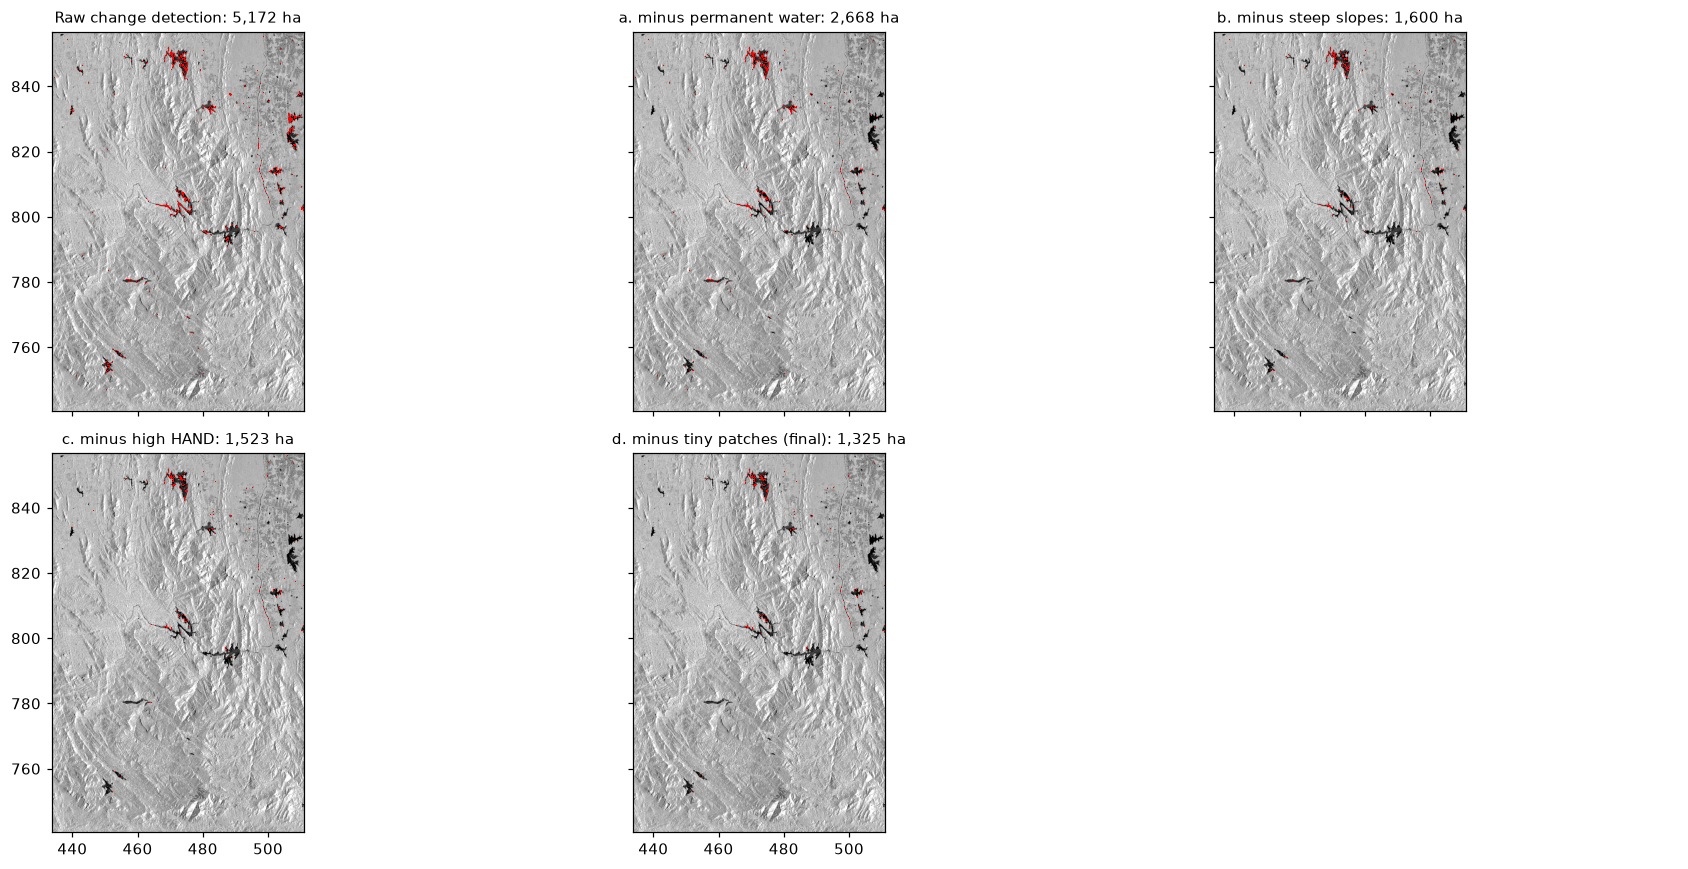

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True, sharey=True)
red = ListedColormap(["none", "red"])
for ax, m, t in zip(axes.ravel(), [flood_raw, step_a, step_b, step_c, flood], steps["Step"]):
    ax.imshow(post_vv_f, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
    ax.imshow(m.astype(int), cmap=red, vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")
    ax.set_title(f"{t}: {ha(m):,.0f} ha", fontsize=10)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_cleaning_steps.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
flood_ha  = ha(flood)
flood_km2 = flood_ha / 100
aoi_km2   = valid.sum() * PIXEL_AREA / 1e6
perm_km2  = (perm_water & valid).sum() * PIXEL_AREA / 1e6

print(f"Study area analysed      : {aoi_km2:,.0f} km²")
print(f"Permanent water (rivers) : {perm_km2:,.0f} km²")
print(f"FLOODED AREA             : {flood_ha:,.0f} ha  =  {flood_km2:,.1f} km²")
print(f"Share of study area      : {100*flood_km2/aoi_km2:.1f} %")

Study area analysed      : 8,973 km²
Permanent water (rivers) : 97 km²
FLOODED AREA             : 1,325 ha  =  13.3 km²
Share of study area      : 0.1 %


In [15]:
WC_CLASSES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
              50: "Built-up", 60: "Bare / sparse", 80: "Permanent water",
              90: "Herbaceous wetland", 95: "Mangroves"}

rows = []
for code_, name in WC_CLASSES.items():
    cls = (lc == code_) & valid
    if cls.sum() == 0:
        continue
    rows.append({"Land cover": name,
                 "Total area (ha)": ha(cls),
                 "Flooded (ha)": ha(cls & flood),
                 "% of class flooded": 100 * (cls & flood).sum() / cls.sum()})

exposure = pd.DataFrame(rows).sort_values("Flooded (ha)", ascending=False).round(1)
exposure.to_csv(f"{OUT_DIR}/flood_by_landcover.csv", index=False)
exposure

,Land cover,Total area (ha),Flooded (ha),% of class flooded
6,Permanent water,14344.1,854.8,6.0
2,Grassland,86270.8,314.7,0.4
3,Cropland,55724.6,110.9,0.2
0,Tree cover,732537.0,37.9,0.0
7,Herbaceous wetland,65.2,5.9,9.1
5,Bare / sparse,235.0,0.8,0.3
1,Shrubland,6.4,0.2,3.1
4,Built-up,8146.2,0.0,0.0


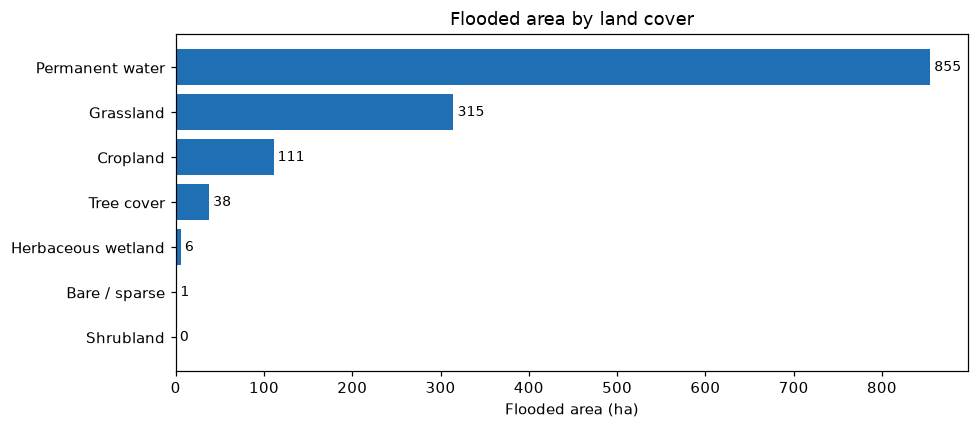

Flooded cropland: 111 ha


In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
e = exposure[exposure["Flooded (ha)"] > 0]
ax.barh(e["Land cover"], e["Flooded (ha)"], color="#1f6fb4")
ax.invert_yaxis()
ax.set_xlabel("Flooded area (ha)")
ax.set_title("Flooded area by land cover")
for y, v in enumerate(e["Flooded (ha)"]):
    ax.text(v, y, f" {v:,.0f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_landcover_exposure.png", dpi=200, bbox_inches="tight")
plt.show()

crop_ha = exposure.loc[exposure["Land cover"] == "Cropland", "Flooded (ha)"].sum()
print(f"Flooded cropland: {crop_ha:,.0f} ha")

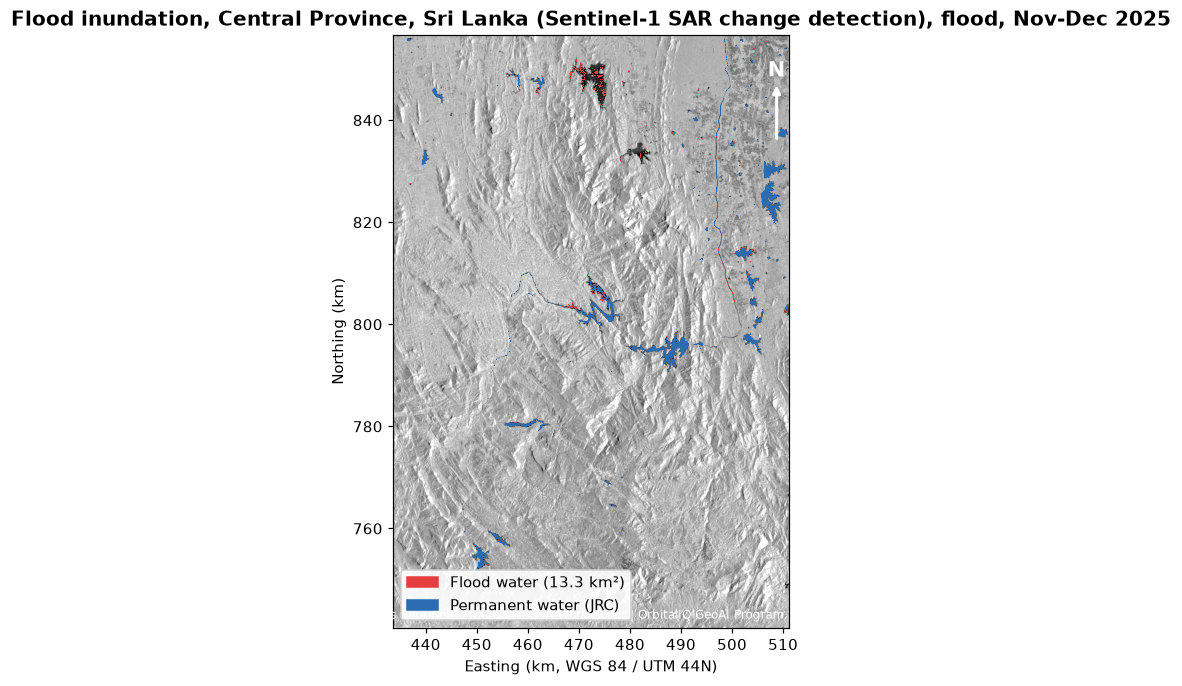

In [17]:
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(post_vv_f, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
ax.imshow((perm_water & valid).astype(int), cmap=ListedColormap(["none", "#2b6cb0"]),
          vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")
ax.imshow(flood.astype(int), cmap=ListedColormap(["none", "#e53e3e"]),
          vmin=0, vmax=1, extent=EXTENT, interpolation="nearest")

ax.legend(handles=[Patch(color="#e53e3e", label=f"Flood water ({flood_km2:,.1f} km²)"),
                   Patch(color="#2b6cb0", label="Permanent water (JRC)")],
          loc="lower left", framealpha=0.9)
ax.set_title(f"Flood inundation, Central Province, Sri Lanka (Sentinel-1 SAR change detection), {POST_LABEL}",
             fontsize=13, weight="bold")
ax.set_xlabel("Easting (km, WGS 84 / UTM 44N)"); ax.set_ylabel("Northing (km)")
ax.annotate("N", xy=(0.97, 0.93), xycoords="axes fraction", ha="center",
            fontsize=14, weight="bold", color="white")
ax.annotate("", xy=(0.97, 0.92), xytext=(0.97, 0.82), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-|>", color="white", lw=2))
ax.text(0.99, 0.01, "Data: Copernicus Sentinel-1, JRC GSW, ESA WorldCover | OrbitalIQ GeoAI Program",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color="white")
plt.savefig(f"{OUT_DIR}/08_final_flood_map.png", dpi=250, bbox_inches="tight")
plt.show()

In [18]:
# Save flood map (1 = flood, 0 = no flood, 255 = outside study area) as GeoTIFF
import rasterio
mask_out = np.where(valid, flood.astype("uint8"), 255).astype("uint8")
with rasterio.open(f"{OUT_DIR}/flood_mask.tif", "w", driver="GTiff",
                   height=mask_out.shape[0], width=mask_out.shape[1], count=1, dtype="uint8",
                   crs=pre.rio.crs, transform=pre.rio.transform(), nodata=255, compress="lzw") as dst:
    dst.write(mask_out, 1)
print("Saved", f"{OUT_DIR}/flood_mask.tif")
DISTRICT_FILE = "gadm41_LKA_2.shp"      # GADM level 2 = districts (optional)
NAME_FIELD    = "NAME_2"
DISTRICTS     = ["Kandy", "Matale", "NuwaraEliya", "Nuwara Eliya"]   # GADM may write it without a space

if os.path.exists(DISTRICT_FILE):
    os.environ["SHAPE_RESTORE_SHX"] = "YES"   # rebuild a missing .shx index file
    import geopandas as gpd
    from rasterio import features

    gdf = gpd.read_file(DISTRICT_FILE).to_crs(pre.rio.crs)
    gdf = gdf[gdf[NAME_FIELD].isin(DISTRICTS)].reset_index(drop=True)
    ids = features.rasterize(
        ((geom, i + 1) for i, geom in enumerate(gdf.geometry)),
        out_shape=flood.shape, transform=pre.rio.transform(), fill=0, dtype="int32")

    gdf["analysed_km2"] = [((ids == i + 1) & valid).sum() * PIXEL_AREA / 1e6 for i in range(len(gdf))]
    gdf["flooded_ha"]   = [((ids == i + 1) & flood).sum() * PIXEL_AREA / 1e4 for i in range(len(gdf))]
    district_table = (gdf.loc[gdf["analysed_km2"] > 0, [NAME_FIELD, "analysed_km2", "flooded_ha"]]
                         .sort_values("flooded_ha", ascending=False).round(1))
    district_table.to_csv(f"{OUT_DIR}/flood_by_district.csv", index=False)
    display(district_table)
else:
    print(f"No district file found at '{DISTRICT_FILE}', skipping the district table.")

Saved flood_outputs/flood_mask.tif
No district file found at 'gadm41_LKA_2.shp', skipping the district table.
